# 06. Học không giám sát: phân khúc thị trường bằng K-Means và PCA

**Mục tiêu học:** dùng gom cụm để khám phá cấu trúc thị trường xe cũ (không dùng nhãn), dùng PCA để nhìn dữ liệu nhiều chiều và hiểu khi nào giảm chiều giúp ích cho mô hình dự đoán.

**Liên hệ lý thuyết:** `Clustering.ipynb`, `PCA.ipynb` (thư mục MACHINE_LEARNING).

**Nội dung**
1. Chuẩn bị đặc trưng cho gom cụm
2. Chọn số cụm
3. Mô tả (profile) từng phân khúc
4. PCA: nhìn dữ liệu trong 2 chiều
5. PCA trên toàn bộ đặc trưng
6. Giảm chiều có giúp mô hình dự đoán không?
7. Phát hiện tin bất thường

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

from used_car_price.config import FEATURES, CATEGORICAL, NUMERIC, TARGET, RANDOM_STATE, RAW_PATH, TEST_SIZE
from used_car_price.data import load_data
from used_car_price.features import build_preprocessor
from used_car_price.train import log_target, candidates
from used_car_price.metrics import evaluate

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (7, 4.2)

df = load_data(); X, y = df[FEATURES], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

## 1. Chuẩn bị đặc trưng cho gom cụm

Gom cụm dựa vào **khoảng cách**, nên phải chuẩn hoá. Ta dùng bốn đặc trưng số mô tả "phân khúc": `log(giá)`, `tuổi`, `log(km)`, `số chỗ`. (Dùng log vì giá và km lệch phải; nếu không, vài xe sang chi phối khoảng cách.)

In [2]:
seg = df.copy()
seg["log_price"] = np.log(seg[TARGET]); seg["log_km"] = np.log1p(seg["km"])
cols = ["log_price", "age", "log_km", "seats"]
Z = StandardScaler().fit_transform(seg[cols])
print("Dạng ma trận:", Z.shape)

Dạng ma trận: (2849, 4)


## 2. Chọn số cụm

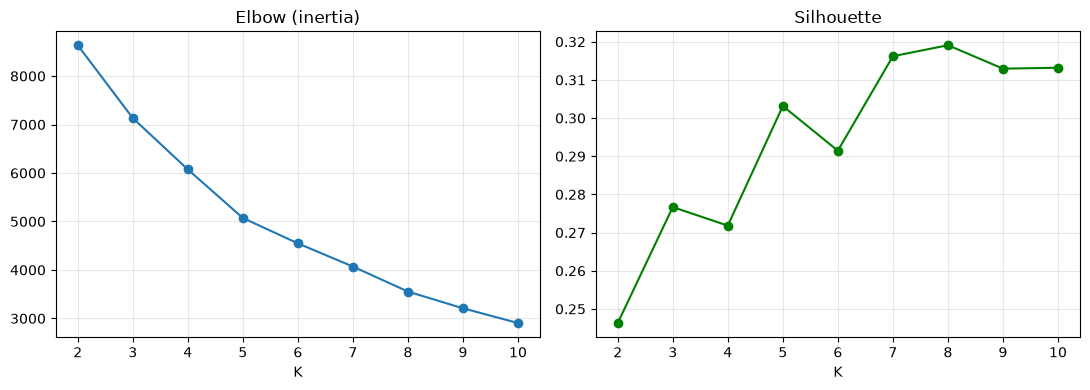

{2: 0.246, 3: 0.277, 4: 0.272, 5: 0.303, 6: 0.291, 7: 0.316, 8: 0.319, 9: 0.313, 10: 0.313}


In [3]:
ks = range(2, 11); inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=0).fit(Z); inertia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("K")
ax[1].plot(ks, sil, "o-", c="g"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("K")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print({k: round(s, 3) for k, s in zip(ks, sil)})

**Lưu ý trung thực:** với dữ liệu thị trường, các điểm trải liên tục nên **không có khuỷu rõ ràng** và silhouette không quá cao. Chọn K là phán đoán: dựa vào số liệu *và* việc cụm có **dễ diễn giải/hữu ích** không. Ta chọn K = 4 để minh hoạ.

## 3. Mô tả từng phân khúc

In [4]:
K = 4
km = KMeans(K, n_init=10, random_state=0).fit(Z); seg["cụm"] = km.labels_
prof = seg.groupby("cụm").agg(số_xe=(TARGET, "size"), giá_trung_vị=(TARGET, "median"), tuổi_trung_vị=("age", "median"),
                              km_trung_vị=("km", "median"), số_chỗ_trung_vị=("seats", "median"))
prof["hãng phổ biến"] = seg.groupby("cụm")["brand"].agg(lambda s: ", ".join(s.value_counts().head(3).index))
prof["% nhập khẩu"] = (seg.assign(imp=(seg["origin"] == "nhập khẩu")).groupby("cụm")["imp"].mean() * 100).round(0)
display(prof.round(0).sort_values("giá_trung_vị"))

,số_xe,giá_trung_vị,tuổi_trung_vị,km_trung_vị,số_chỗ_trung_vị,hãng phổ biến,% nhập khẩu
cụm,,,,,,,
1,558,390.0,11.0,100000.0,5.0,"Toyota, Mercedes Benz, Hyundai",47.0
2,951,565.0,4.0,48000.0,5.0,"VinFast, Toyota, Hyundai",31.0
3,796,799.0,4.0,62700.0,7.0,"Toyota, Kia, Mitsubishi",53.0
0,544,2160.0,3.0,19400.0,5.0,"Mercedes Benz, Porsche, Lexus",63.0


**Việc của bạn:** đặt tên cho từng cụm theo đặc điểm (vd. "xe nhỏ cũ giá rẻ", "SUV/MPV 7 chỗ tầm trung", "xe sang"). Đây là phần **diễn giải** mà thuật toán không làm thay được.

Kiểm tra độ ổn định: chạy lại với seed khác, các cụm có giống không? So sánh K-Means với GMM và phân cấp bằng chỉ số ARI.

In [5]:
from sklearn.metrics import adjusted_rand_score
km2 = KMeans(K, n_init=10, random_state=7).fit(Z)
gm = GaussianMixture(K, random_state=0, n_init=3).fit(Z); ag = AgglomerativeClustering(K, linkage="ward").fit(Z)
print("ARI K-Means (seed 0 vs seed 7):", round(adjusted_rand_score(km.labels_, km2.labels_), 3))
print("ARI K-Means vs GMM            :", round(adjusted_rand_score(km.labels_, gm.predict(Z)), 3))
print("ARI K-Means vs Agglomerative  :", round(adjusted_rand_score(km.labels_, ag.labels_), 3))

ARI K-Means (seed 0 vs seed 7): 0.966
ARI K-Means vs GMM            : 0.357
ARI K-Means vs Agglomerative  : 0.562


## 4. PCA: nhìn dữ liệu trong 2 chiều

Tỉ lệ phương sai giải thích: [0.408 0.26 ] | tổng: 0.668
     log_price   age  log_km  seats
PC1      -0.46  0.64    0.61   0.10
PC2       0.34 -0.09    0.21   0.91


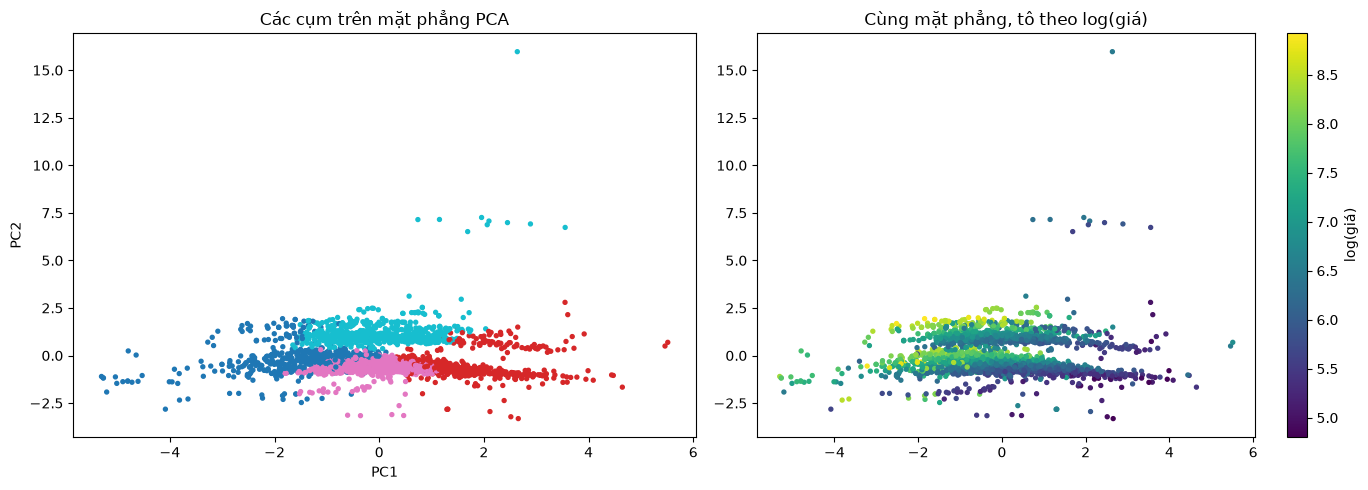

In [6]:
pca = PCA(2).fit(Z); P = pca.transform(Z)
print("Tỉ lệ phương sai giải thích:", pca.explained_variance_ratio_.round(3), "| tổng:", pca.explained_variance_ratio_.sum().round(3))
print(pd.DataFrame(pca.components_, columns=cols, index=["PC1", "PC2"]).round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sc = ax[0].scatter(P[:, 0], P[:, 1], c=seg["cụm"], cmap="tab10", s=8); ax[0].set_title("Các cụm trên mặt phẳng PCA"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
sc2 = ax[1].scatter(P[:, 0], P[:, 1], c=seg["log_price"], cmap="viridis", s=8); plt.colorbar(sc2, ax=ax[1], label="log(giá)"); ax[1].set_title("Cùng mặt phẳng, tô theo log(giá)")
plt.tight_layout(); plt.show()

Hệ số (loadings) cho biết mỗi thành phần chính là tổ hợp của các đặc trưng nào. PC1 thường là "mức độ cũ/ đã dùng" đối lập với "đắt/mới".

## 5. PCA trên toàn bộ đặc trưng (one-hot + số)

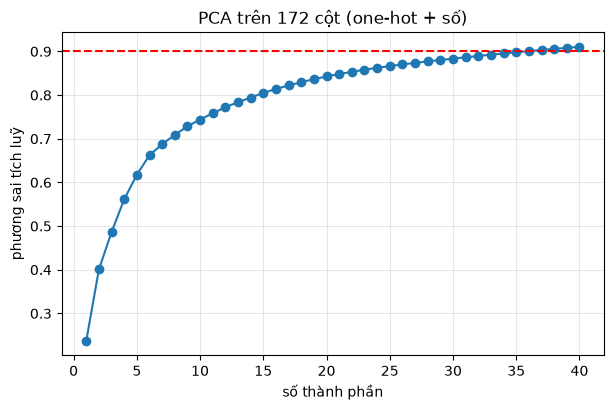

Số thành phần cho 90% phương sai: 36 trên 172 cột


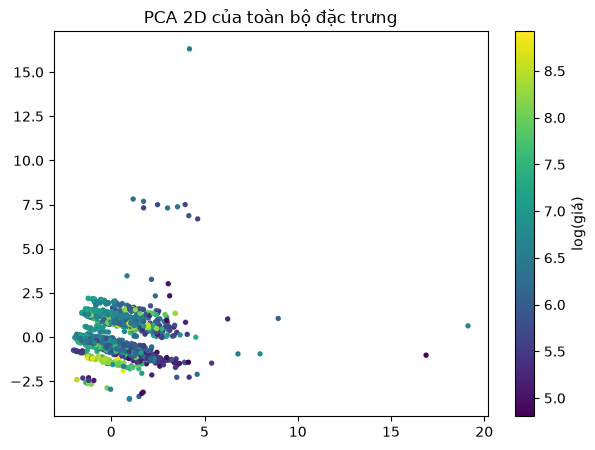

In [7]:
prep = build_preprocessor(True).fit(X)       # one-hot + chuẩn hoá số
M = prep.transform(X).toarray()
full = PCA().fit(M); cum = np.cumsum(full.explained_variance_ratio_)
plt.plot(range(1, 41), cum[:40], "o-"); plt.axhline(.9, c="r", ls="--"); plt.xlabel("số thành phần"); plt.ylabel("phương sai tích luỹ"); plt.grid(alpha=.3); plt.title(f"PCA trên {M.shape[1]} cột (one-hot + số)"); plt.show()
print("Số thành phần cho 90% phương sai:", int(np.argmax(cum >= .9)) + 1, "trên", M.shape[1], "cột")
P2 = PCA(2).fit_transform(M)
plt.figure(figsize=(7, 5)); s = plt.scatter(P2[:, 0], P2[:, 1], c=np.log(y), cmap="viridis", s=8); plt.colorbar(s, label="log(giá)"); plt.title("PCA 2D của toàn bộ đặc trưng"); plt.show()

**Quan sát:** one-hot làm dữ liệu rất **thưa**; phương sai phân tán trên nhiều thành phần, nên 2 chiều giữ rất ít thông tin. PCA tuyến tính không hợp với dữ liệu phân loại nhiều giá trị; với trực quan hoá loại này người ta hay dùng UMAP/t-SNE (nhưng mất tính diễn giải tuyến tính).

## 6. Giảm chiều có giúp mô hình dự đoán không?

In [8]:
rows = []
base = log_target(Pipeline([("prep", build_preprocessor(True)), ("m", Ridge(alpha=1.0))]))
rows.append({"mô hình": f"Ridge trên toàn bộ {M.shape[1]} cột", "MAPE CV": -cross_val_score(base, X_tr, y_tr, cv=5, scoring="neg_mean_absolute_percentage_error").mean()})
for k in [5, 10, 20, 40, 80]:
    m = log_target(Pipeline([("prep", build_preprocessor(True)), ("pca", PCA(k)), ("m", Ridge(alpha=1.0))]))
    rows.append({"mô hình": f"PCA({k}) + Ridge", "MAPE CV": -cross_val_score(m, X_tr, y_tr, cv=5, scoring="neg_mean_absolute_percentage_error").mean()})
r = pd.DataFrame(rows); r["MAPE CV"] = (r["MAPE CV"] * 100).round(2)
display(r)

,mô hình,MAPE CV
0,Ridge trên toàn bộ 172 cột,17.53
1,PCA(5) + Ridge,62.54
2,PCA(10) + Ridge,52.64
3,PCA(20) + Ridge,43.83
4,PCA(40) + Ridge,32.95
5,PCA(80) + Ridge,21.75


**Kết luận điển hình:** PCA **không** giúp ở đây. Phương sai lớn không có nghĩa là thông tin dự đoán giá nhiều (các cột nhỏ như "là Lexus" có phương sai bé nhưng rất quan trọng cho giá). PCA là kỹ thuật **không giám sát**, không biết gì về nhãn. Nên dùng PCA khi: nhiều cột liên tục tương quan mạnh, cần nén/khử nhiễu, hoặc trực quan hoá; không nên mặc định dùng trước mọi mô hình.

## 7. Phát hiện tin bất thường (Isolation Forest)

Tìm các tin có tổ hợp (giá, tuổi, km, số chỗ) hiếm gặp, có thể là lỗi nhập hoặc xe đặc biệt.

In [9]:
iso = IsolationForest(contamination=0.01, random_state=0).fit(Z)
seg["bất thường"] = iso.predict(Z) == -1
display(seg[seg["bất thường"]].sort_values(TARGET)[["brand", "model", "year", "km", "seats", TARGET]].head(15))
print("Số tin bị đánh dấu:", int(seg["bất thường"].sum()), "/", len(seg))

,brand,model,year,km,seats,price_million
2785,Toyota,Hiace,2008,100000.0,10.0,150.0
2803,Toyota,Hiace,2008,79000.0,11.0,150.0
1963,Toyota,Innova,2010,120.0,8.0,165.0
2411,Hyundai,i10,2014,120.0,5.0,190.0
1181,Ford,Transit,2017,30000.0,16.0,270.0
2407,Toyota,Hiace,2011,186767.0,16.0,280.0
2199,Toyota,Vios,2016,1.0,5.0,280.0
2771,Ford,Transit,2019,250000.0,16.0,300.0
2293,Toyota,Venza,2009,82.0,5.0,305.0
2287,Mazda,6,2016,78.0,5.0,338.0


Số tin bị đánh dấu: 29 / 2849


Các tin này đáng được kiểm tra bằng tay: giá quá thấp so với đời xe, km vô lý, v.v. Đây là cách làm sạch dữ liệu có hướng dẫn thay vì chỉ cắt theo phân vị.

## Bài tập
1. Thêm `brand` (mã hoá bằng giá trung vị theo hãng) vào đặc trưng gom cụm. Cụm thay đổi thế nào?
2. Thử `GaussianMixture` với K = 2..8 và chọn K bằng BIC. Có khớp với silhouette không?
3. Dùng `DBSCAN` trên `Z`. Có tìm được vùng "xe sang" như cụm riêng không?
4. Đặt tên cho 4 phân khúc và viết 3 câu mô tả khách hàng điển hình của mỗi phân khúc.
5. Dùng nhãn cụm làm **đặc trưng** thêm cho mô hình dự đoán giá (gom cụm **không dùng giá**, và fit trong pipeline để tránh rò rỉ). Có giúp không?